In [3]:
import matplotlib.pyplot as plt
import numpy as np
import math
import pandas as pd

In [36]:
def close_generator(filepath, step=50):
    """
    Yields every `step`-th closing price from file.
    Memory safe: does not load entire file.
    """
    with open(filepath, 'r') as f:
        for i, line in enumerate(f):
            if i % step != 0:
                continue

            try:
                # Split by semicolon
                parts = line.strip().split(';')
                close = float(parts[3])   # close is index 3
                yield close
            except (IndexError, ValueError):
                continue


def ultimate_smoother(prices, critical_period=250):
    """
    Ehlers Ultimate Smoother
    Replicates your NinjaScript filter logic.
    """

    prices = np.array(prices)
    n = len(prices)

    # Coefficients
    a1 = math.exp(-1.414 * math.pi / critical_period)
    c2 = 2.0 * a1 * math.cos(1.414 * math.pi / critical_period)
    c3 = -a1 * a1
    c1 = (1.0 + c2 - c3) / 4.0

    filt = np.zeros(n)

    for i in range(n):
        if i < 4:
            filt[i] = prices[i]
        else:
            filt[i] = (
                (1.0 - c1) * prices[i]
                + (2.0 * c1 - c2) * prices[i-1]
                - (c1 + c3) * prices[i-2]
                + c2 * filt[i-1]
                + c3 * filt[i-2]
            )

    return filt


def highpass_2nd_order(prices, critical_period=250):
    filtered = ultimate_smoother(prices, critical_period)
    return prices - filtered

In [4]:
filepath = "./ESTick.txt"  # change this

# Collect downsampled closes
closes = list(close_generator(filepath, step=50))

print("Loaded bars:", len(closes))

slopeLookback = 5
volWindow = 250
# Apply filter
fastFilter = ultimate_smoother(closes, critical_period=50)
mediumFilter = ultimate_smoother(closes, critical_period=250)
slowFilter = ultimate_smoother(closes, critical_period=1250)

combined_filter = fastFilter * 0.3 + mediumFilter * 0.7
slopes = np.diff(combined_filter, slopeLookback)
stddev = pd.Series(slopes).rolling(window=volWindow).std()
normalized_slope = slopes / stddev

# Create a clean dictionary where all arrays are aligned
data = {
    'slope': normalized_slope[volWindow:]
}

df = pd.DataFrame(data)
# df.replace([np.inf, -np.inf], np.nan, inplace=True)
df = df.dropna()

Loaded bars: 460670


In [ ]:
import numpy as np
import pandas as pd
from hmmlearn import hmm

# 1. Prepare your data
# 'signal' is your normalized slope vector (N,)
# hmmlearn expects shape (N, 1)
data = df.values
latent_states = 3
# 2. Define and Fit the HMM
# n_components=3 (Uptrend, Downtrend, Sideways)
# covariance_type='diag' allows each state to have its own variance
model = hmm.GaussianHMM(n_components=latent_states, covariance_type="diag", n_iter=1000)
model.fit(data)

# 3. Predict the hidden states
hidden_states = model.predict(data)

# 4. Interpret the states
# Because the HMM is unsupervised, it doesn't know which state is "Up" or "Down"
# We look at the means of the Gaussians to map them
for i in range(latent_states):
    print(f"State {i} mean: {model.means_[i]}")
    print(f"State {i} variance: {np.diag(model.covars_[i])}")

# 5. Look at the discovered logic
print("Transition Matrix:\n", model.transmat_)
# print("Means of states:\n", state_means_)

Loaded bars: 92134
200.34362599686062 1.1974780225779975 -6.934845362286632


C:\Users\ryany\AppData\Local\Temp\ipykernel_152376\1372602366.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


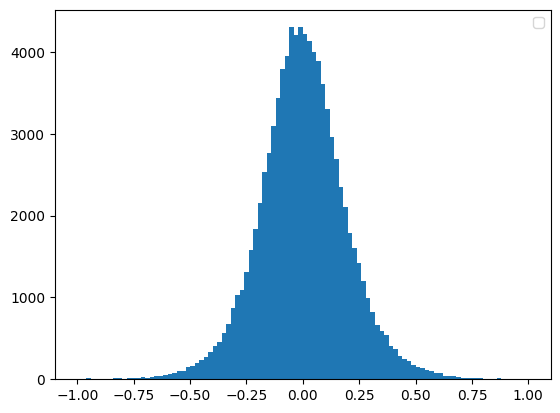

-2.7578268859650765 0.7838771780880404


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, kurtosis

# --- Setup and Filtering ---
closes = np.array(list(close_generator(filepath, step=250)))

# 1. Roofing Filter Stage 1: High Pass (Detrending)
# This centers the data at zero.
hp = highpass_2nd_order(closes, critical_period=250)

# 2. Roofing Filter Stage 2: SuperSmoother (Denoising)
# This removes the high-frequency jitter (the 'needle' in your histogram)
# We use a shorter period to avoid adding too much lag.
roofed_signal = ultimate_smoother(hp, critical_period=20) 

# 3. Normalization (Required for Fisher)
# We use a rolling Min/Max to force the signal into a U-shape between -1 and 1
def rolling_normalize(data, window=50):
    series = pd.Series(data)
    r_min = series.rolling(window).min()
    r_max = series.rolling(window).max()
    # Scale to -1 to 1, and clip slightly to avoid log(0) in Fisher
    normalized = 2 * ((series - r_min) / (r_max - r_min)) - 1
    return normalized.clip(-0.999, 0.999).fillna(0).values

# Normalize the roofed signal to prepare it for the Fisher Transform
norm_signal = rolling_normalize(roofed_signal, window=100)

# 4. Fisher Transform
# This stretches the U-shape into a Gaussian Bell Curve
fisher_transformed = 0.5 * np.log((1 + norm_signal) / (1 - norm_signal))

# --- Visualization ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: The Histogram
# We plot the Fisher result. Note the x-range expands because Fisher is non-linear.
ax1.hist(fisher_transformed, bins=100, color='royalblue', alpha=0.7, density=True)
ax1.set_title(f"Fisher Transformed Distribution\nKurtosis: {kurtosis(fisher_transformed):.2f}")

# Plot 2: Overlaying the Normal Curve
mu, std = fisher_transformed.mean(), fisher_transformed.std()
x = np.linspace(fisher_transformed.min(), fisher_transformed.max(), 200)
p = norm.pdf(x, mu, std)
ax1.plot(x, p, 'r-', linewidth=2, label='Normal Fit')

# Stats Output
print(f"Final Kurtosis: {kurtosis(fisher_transformed)}")
print(f"0.1th Percentile: {np.percentile(fisher_transformed, 0.1):.3f}")
print(f"99.9th Percentile: {np.percentile(fisher_transformed, 99.9):.3f}")

plt.legend()
plt.show()

--- Distribution Report ---
Mean:     -0.119043
Std Dev:  4.952269
Skewness: -9.15 (Positive=Right tail, Negative=Left tail)
Kurtosis: 200.34 (Normal=0, Yours is extreme!)
Max Move: 26.41 Standard Deviations

--- Tail Probability vs. Gaussian ---
Events > 3σ: 0.3983%  (Gaussian: 0.2700%)
Events > 6σ: 0.1454%  (Gaussian: 0.0000002%)
Jarque-Bera p-value: 0.000000e+00 (If < 0.05, definitely not Gaussian)


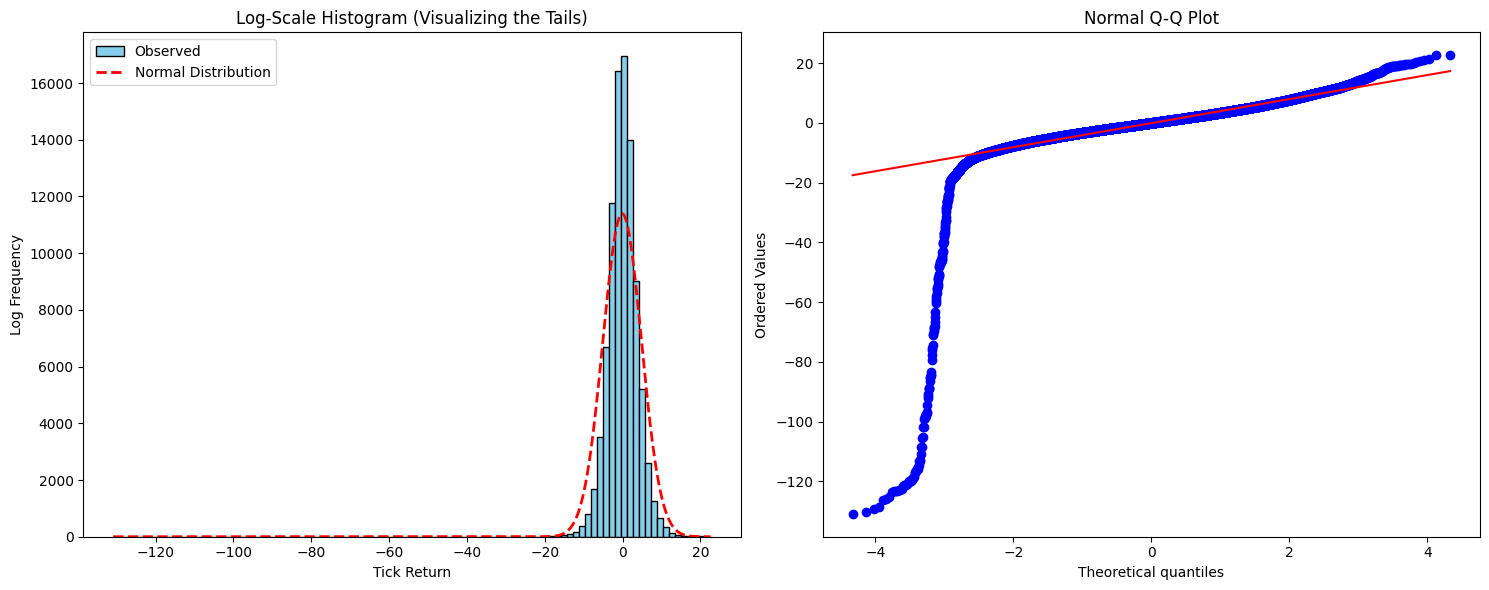

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def describe_distribution(data):
    # Basic Stats
    mu = np.mean(data)
    std = np.std(data)
    kurt = stats.kurtosis(data) # excess kurtosis (Fisher’s)
    skew = stats.skew(data)
    
    # Normality Tests
    jb_stat, jb_p = stats.jarque_bera(data)
    
    # Tail Analysis - How many "Sigmas" are the extremes?
    z_scores = (data - mu) / std
    max_z = np.max(np.abs(z_scores))
    
    # Outlier Counts
    outliers_3s = np.sum(np.abs(z_scores) > 3) / len(data) * 100
    outliers_6s = np.sum(np.abs(z_scores) > 6) / len(data) * 100
    
    print(f"--- Distribution Report ---")
    print(f"Mean:     {mu:.6f}")
    print(f"Std Dev:  {std:.6f}")
    print(f"Skewness: {skew:.2f} (Positive=Right tail, Negative=Left tail)")
    print(f"Kurtosis: {kurt:.2f} (Normal=0, Yours is extreme!)")
    print(f"Max Move: {max_z:.2f} Standard Deviations")
    print(f"\n--- Tail Probability vs. Gaussian ---")
    print(f"Events > 3σ: {outliers_3s:.4f}%  (Gaussian: 0.2700%)")
    print(f"Events > 6σ: {outliers_6s:.4f}%  (Gaussian: 0.0000002%)")
    print(f"Jarque-Bera p-value: {jb_p:.6e} (If < 0.05, definitely not Gaussian)")

    # Visualization
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

    # 1. Log-Scale Histogram (Crucial for Kurtosis = 500)
    # This lets you see the 'slabs' (tails) that are invisible on linear scales
    counts, bins, _ = ax1.hist(data, bins=100, color='skyblue', edgecolor='black', log=False, label='Observed')
    
    # Overlay Normal Curve on Log Scale
    x = np.linspace(min(data), max(data), 1000)
    p = stats.norm.pdf(x, mu, std)
    ax1.plot(x, p * len(data) * (bins[1]-bins[0]), 'r--', lw=2, label='Normal Distribution')
    ax1.set_title("Log-Scale Histogram (Visualizing the Tails)")
    ax1.set_xlabel("Tick Return")
    ax1.set_ylabel("Log Frequency")
    ax1.legend()

    # 2. Q-Q Plot
    stats.probplot(data, dist="norm", plot=ax2)
    ax2.set_title("Normal Q-Q Plot")
    
    plt.tight_layout()
    plt.show()

# Run it on your diffs
describe_distribution(diffs)

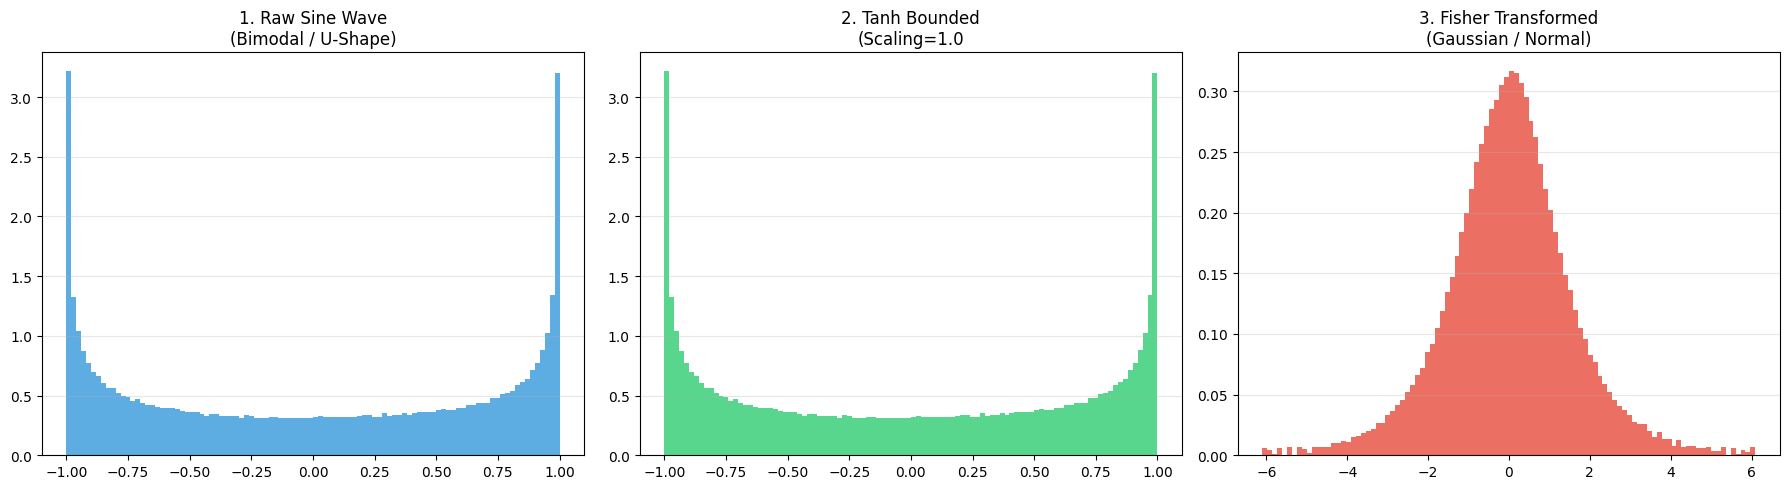

In [35]:
# 1. Generate a pure Sine Wave (The Ideal Cycle)
# In trading, this would be your Bandpass Filtered or Detrended data.
t = np.linspace(0, 100, 10000)
sine_wave = np.sin(t)

# 2. Apply Tanh Bounding
# We scale the sine wave before tanh to control how "pushed" the U-shape is.
# tanh(x) ensures the value is strictly between -1 and 1.
# bounded_signal = np.tanh(sine_wave)
bounded_signal = sine_wave * 0.99999
# 3. Apply the Fisher Transform
# Formula: y = 0.5 * ln((1 + x) / (1 - x))
# Note: tanh prevents x from ever reaching 1.0, so we avoid division by zero.
fisher_transformed = 0.5 * np.log((1 + bounded_signal) / (1 - bounded_signal))

# --- Visualization ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

# Plot 1: Raw Sine Wave (Bimodal / U-Shaped)
axes[0].hist(sine_wave, bins=100, color='#3498db', alpha=0.8, density=True)
axes[0].set_title("1. Raw Sine Wave\n(Bimodal / U-Shape)")
axes[0].grid(axis='y', alpha=0.3)

# Plot 2: Tanh Bounded (Still Bimodal)
axes[1].hist(bounded_signal, bins=100, color='#2ecc71', alpha=0.8, density=True)
axes[1].set_title(f"2. Tanh Bounded\n(Scaling=1.0")
axes[1].grid(axis='y', alpha=0.3)

# Plot 3: Fisher Transformed (Gaussian Spike)
axes[2].hist(fisher_transformed, bins=100, color='#e74c3c', alpha=0.8, density=True)
axes[2].set_title("3. Fisher Transformed\n(Gaussian / Normal)")
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()